# Dear Canada — Text Analysis
Word clouds · Word frequency · Sentiment analysis · Bigrams · Keyword-in-context

**Before running:** activate your `dear-canada` conda environment and launch Jupyter from the `Dear Canada/` project root.

Lines marked `# >>>` are yours to edit.

In [20]:
# ── Imports ───────────────────────────────────────────────────────────────────
import sys
sys.path.insert(0, "..")

import importlib
import config
import CLS_utils

importlib.reload(config)
importlib.reload(CLS_utils)

# Force CLS_utils to re-read config rather than use its cached copy
CLS_utils.config = config

from CLS_utils import *
print("Reloaded.")

Reloaded.


In [18]:
# ── Load data ─────────────────────────────────────────────────────────────────
# >>> To load only specific books pass a list, e.g. books=["SofS", "FitS"]
# >>> To load all books registered in config.py, leave as None.

book_dfs, data = load_texts(books=None)   # >>>
db             = load_db(books=None)      # >>>

OK  SofS: 9 chapters loaded.
OK  FitS: 18 chapters loaded.
OK  DRtoF: 14 chapters loaded.
OK  PasWide: 1 chapters loaded.
OK  NbutC: 14 chapters loaded.
OK  AinUTL: 13 chapters loaded.

Total chapters across all books: 69
  Loaded 3,291 rows from AinUTL_sentences.csv
  Loaded 3,135 rows from DRtoF_sentences.csv
  Loaded 1,996 rows from FitS_sentences.csv
  Loaded 2,987 rows from NbutC_sentences.csv
  Loaded 3,337 rows from PasWide_sentences.csv
  Loaded 2,329 rows from SofS_sentences.csv

Combined DB: 17,075 rows | 6 book(s): ['AinUTL', 'DRtoF', 'FitS', 'NbutC', 'PasWide', 'SofS'] | 643 unique entries


---
## 1 · Word clouds

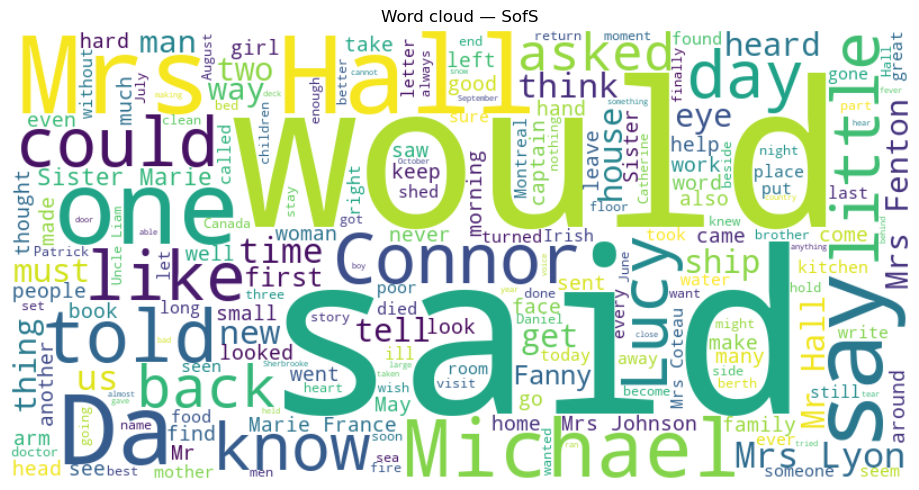

In [3]:
# Word cloud for the full text of one book
# >>> Change BOOK to any key in book_dfs
BOOK = list(book_dfs.keys())[0] if book_dfs else None

if BOOK:
    full_text = " ".join(book_dfs[BOOK]["text"].tolist())
    generate_word_cloud(full_text, label=f"Word cloud — {BOOK}", book_name=BOOK)
else:
    print("No books loaded.")

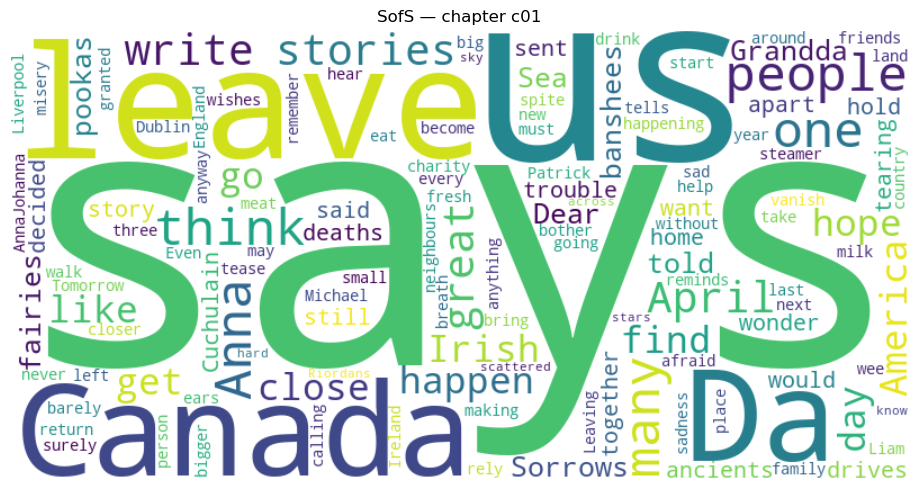

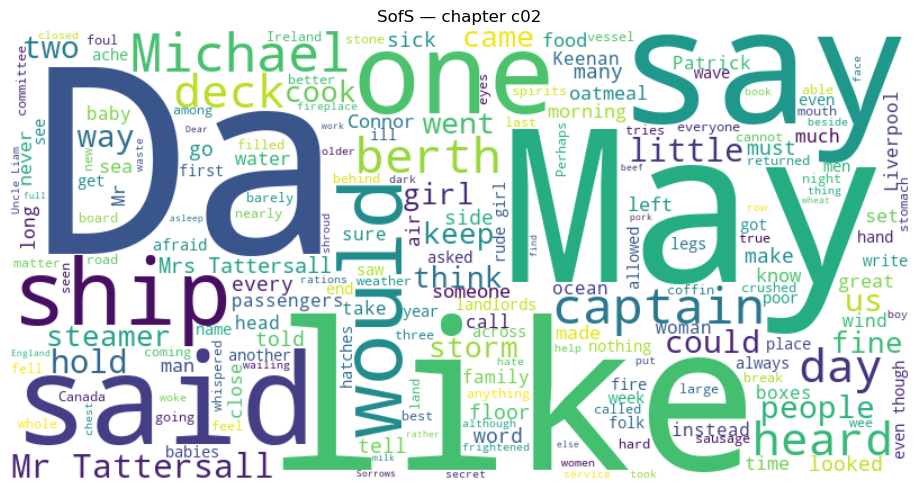

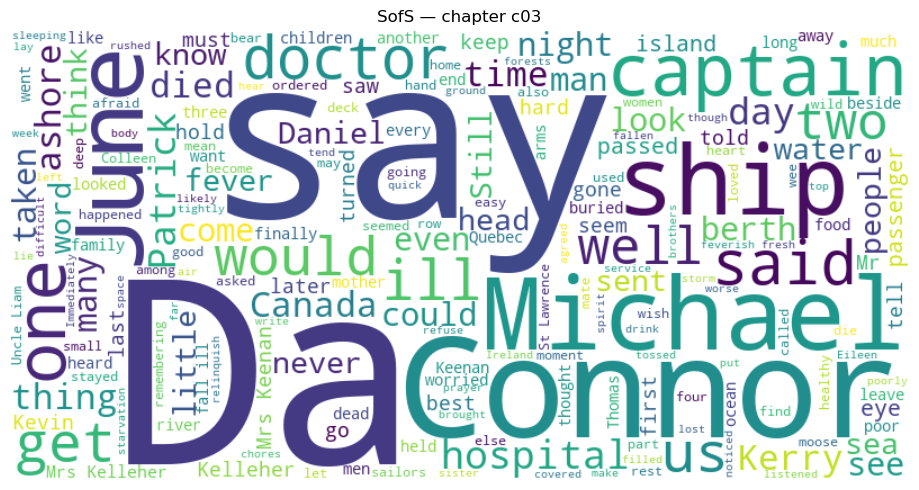

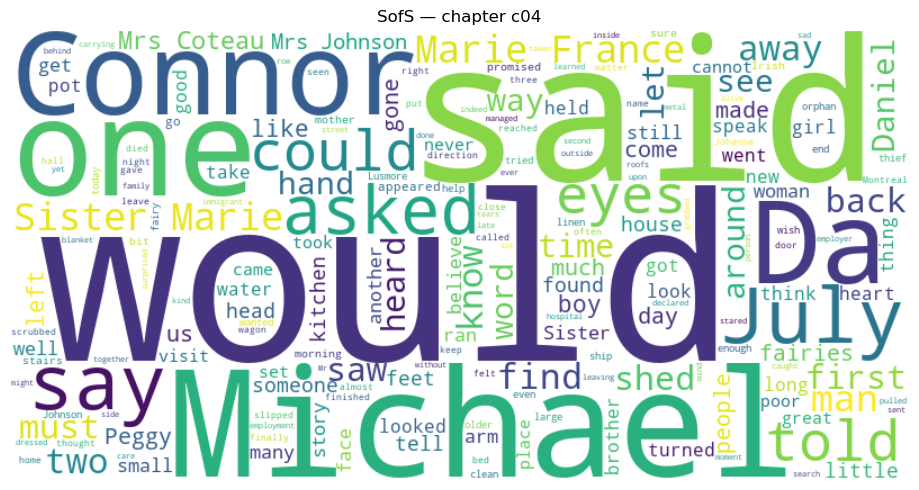

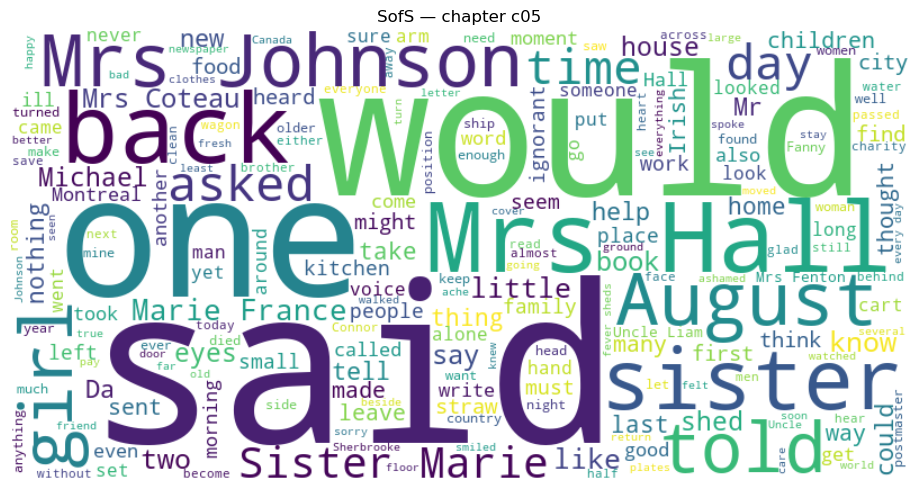

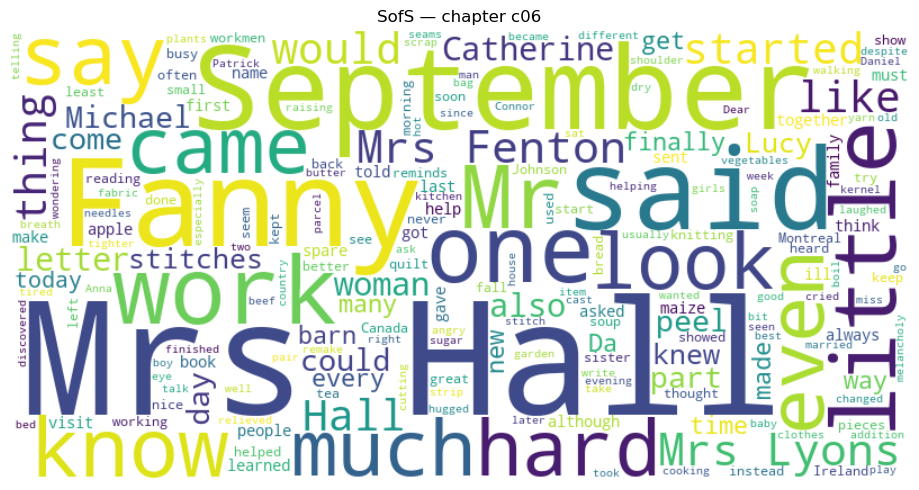

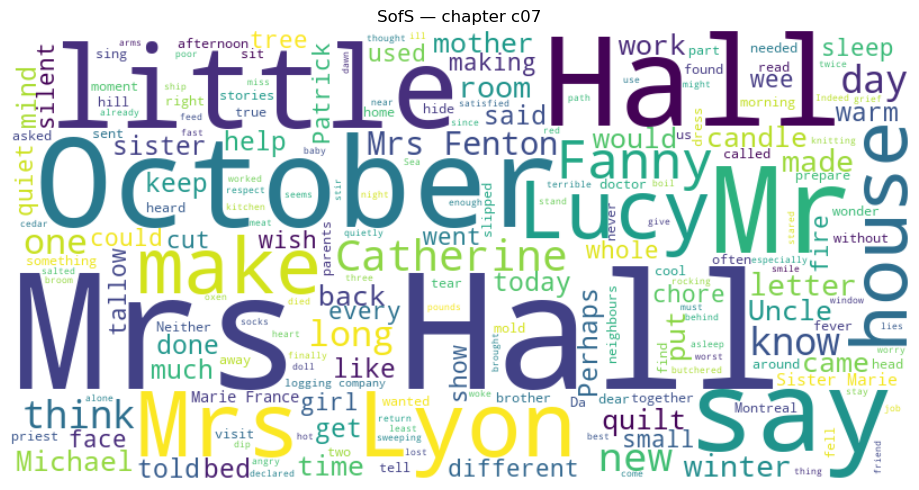

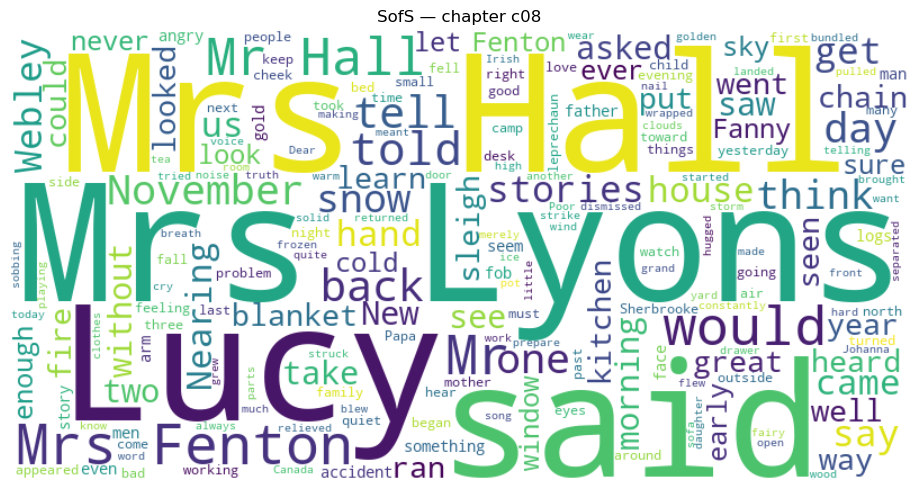

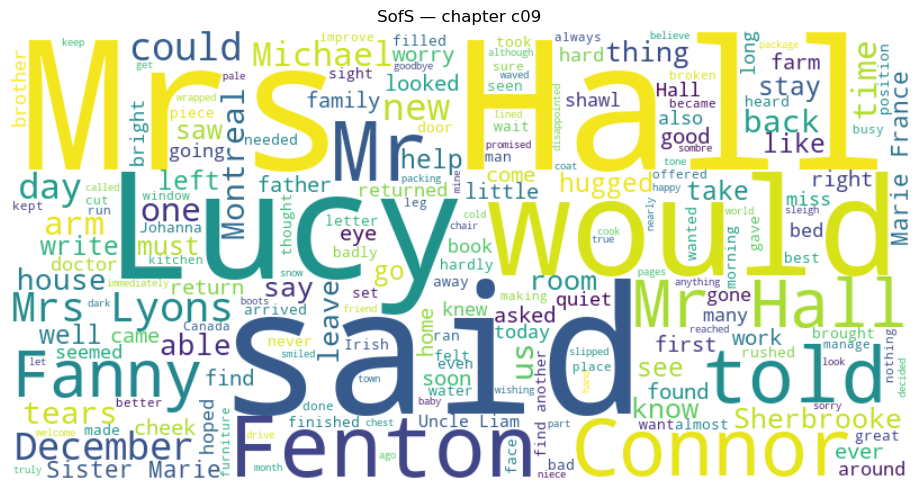

In [4]:
# One word cloud per chapter for a book
# >>> Change BOOK
BOOK = list(book_dfs.keys())[0] if book_dfs else None

if BOOK:
    word_clouds_for_book(BOOK, book_dfs)

---
## 2 · Word frequency over chapters

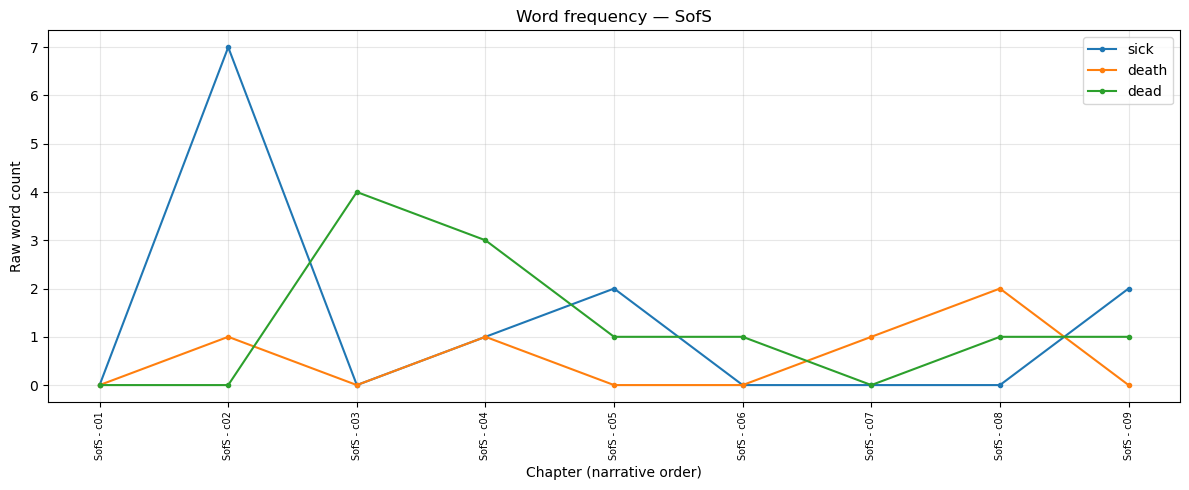

In [ ]:
# >>> Words to track
WORDS_TO_TRACK = [ "sick", "death", "dead", "healthy", "happy"]   # >>>

# >>> Restrict to one book (string), or None for all books together
BOOK_FILTER = "SofS"   # >>>

if data:
    corpus = (
        {k: v for k, v in data.items() if k.startswith(BOOK_FILTER + " -")}
        if BOOK_FILTER else data
    )
    plot_word_frequency(
        corpus, WORDS_TO_TRACK,
        title=f"Word frequency — {BOOK_FILTER or 'all books'}"
    )

---
## 3 · Sentiment analysis

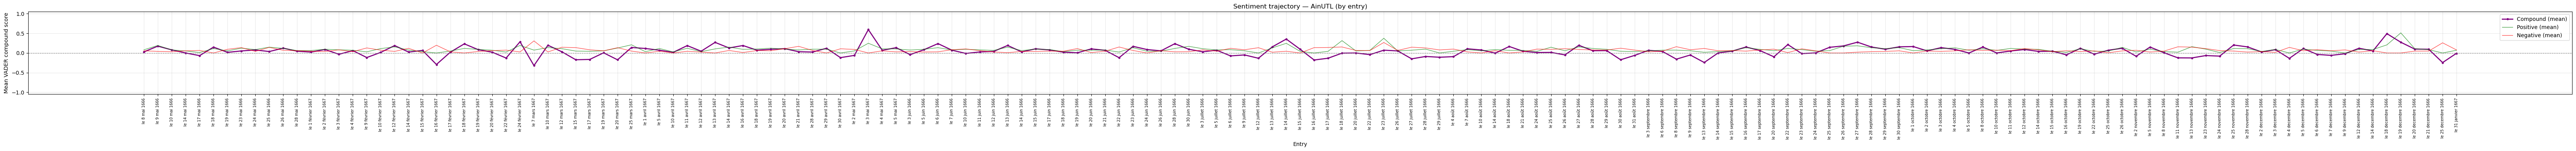

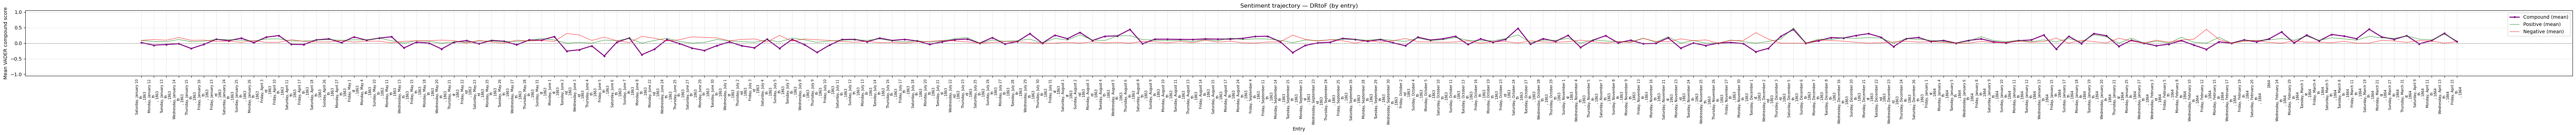

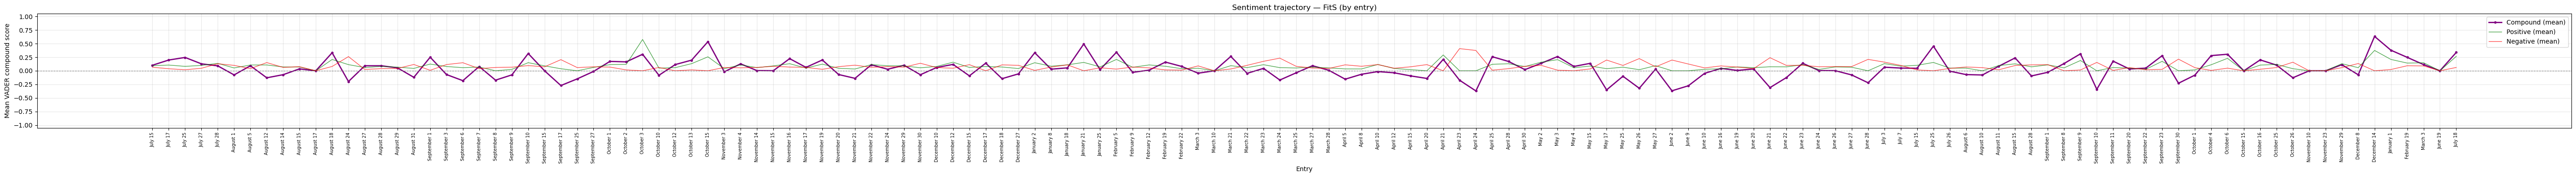

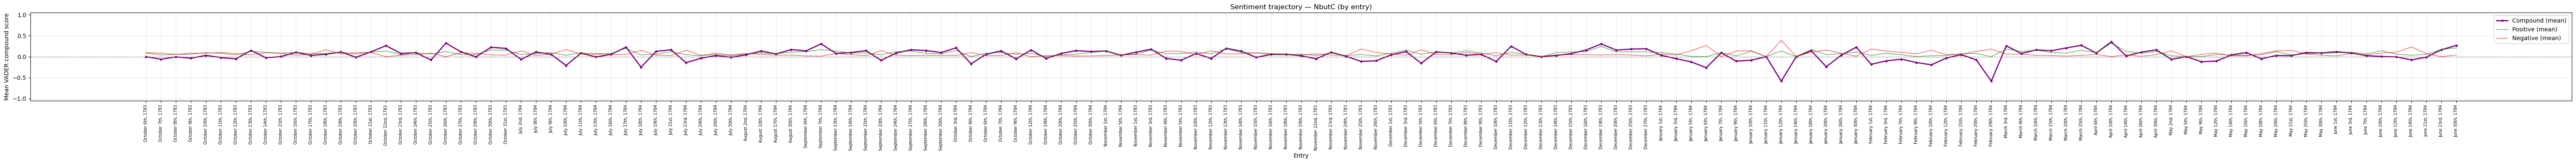

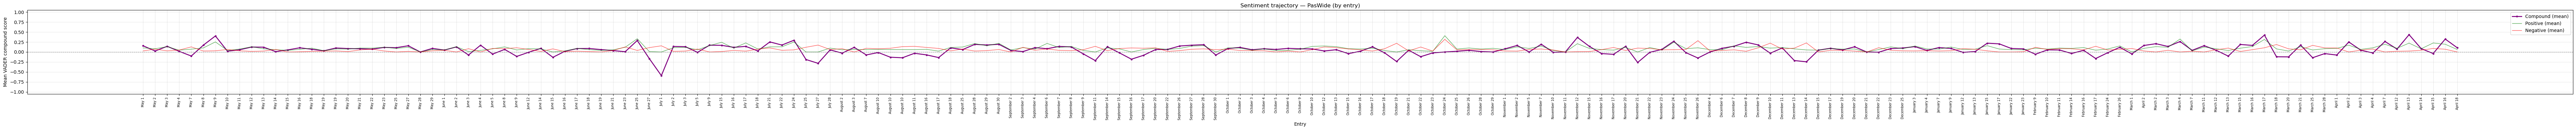

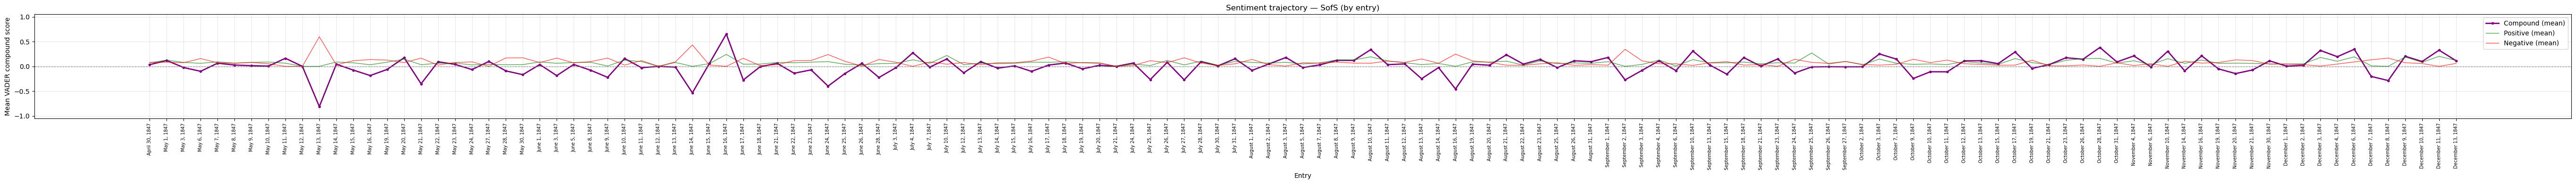

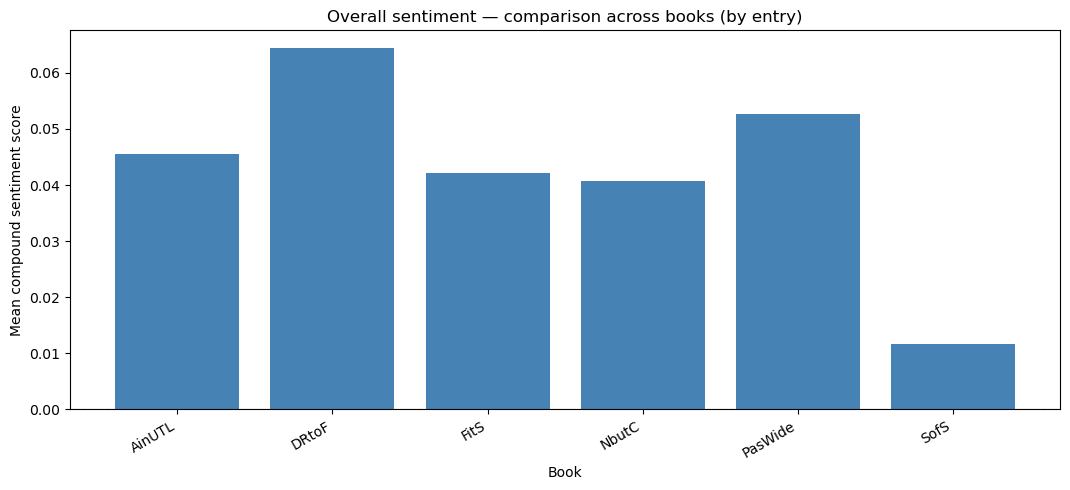

In [ ]:
# >>> Set to a list of book names to restrict, or None for all
BOOKS_FOR_SENTIMENT = None   # e.g. ["SofS", "FitS"]

entry_sentiment = score_sentiment(db, books_to_plot=BOOKS_FOR_SENTIMENT, group_by="entry") 

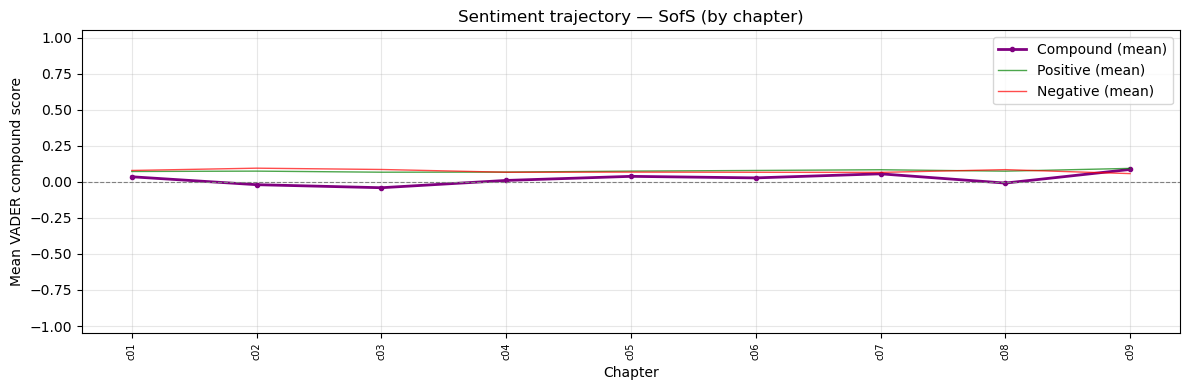

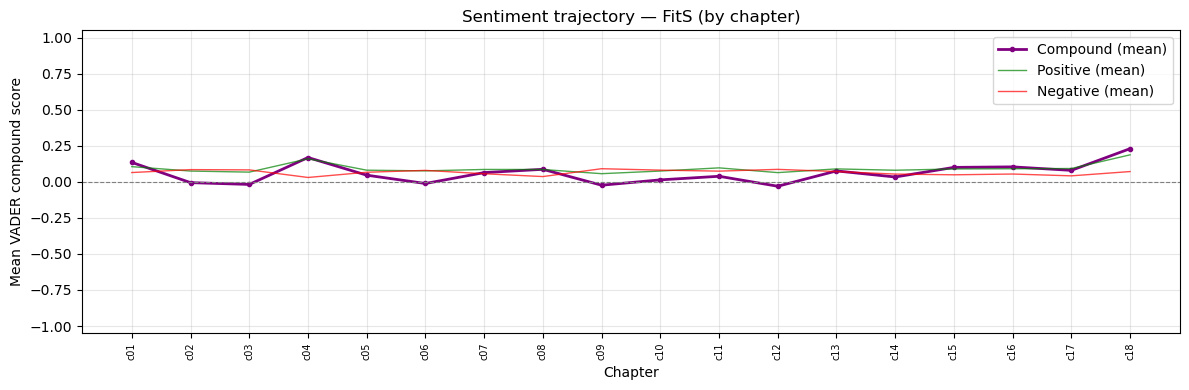

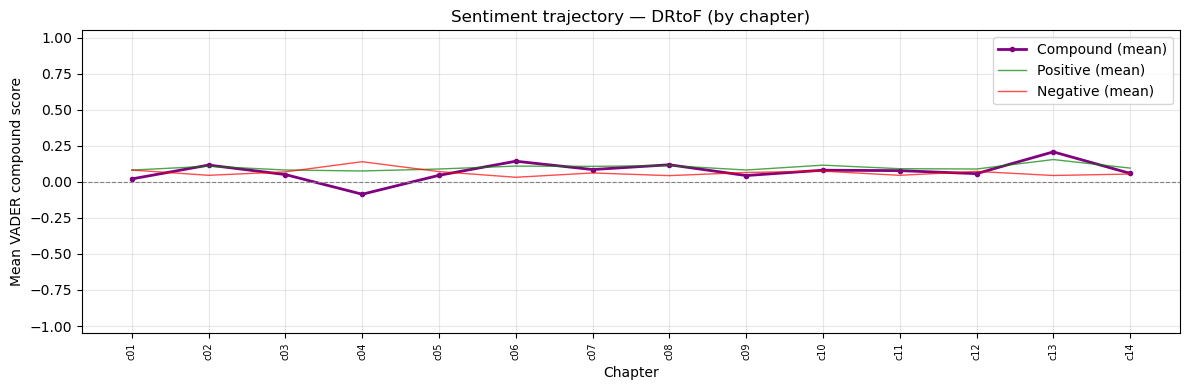

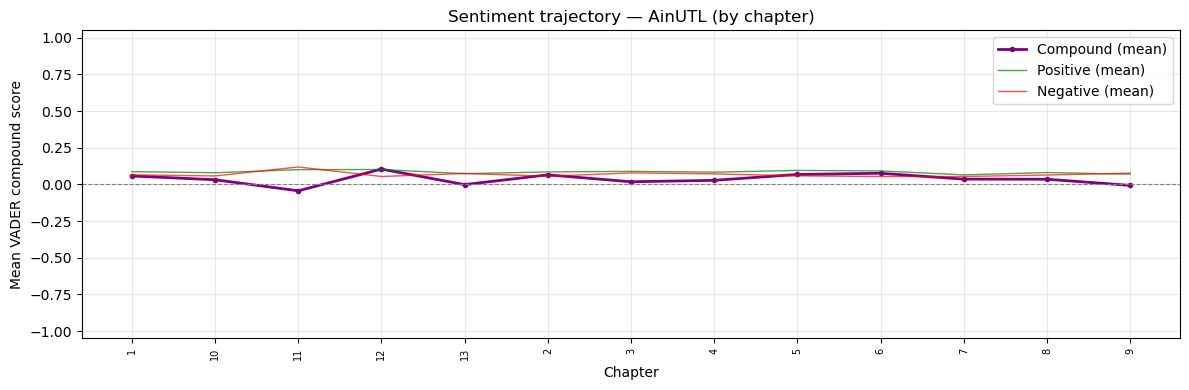

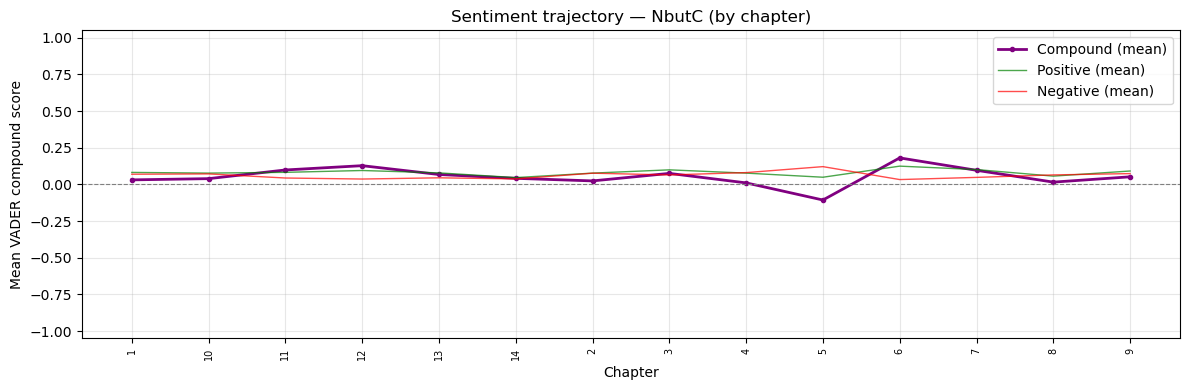

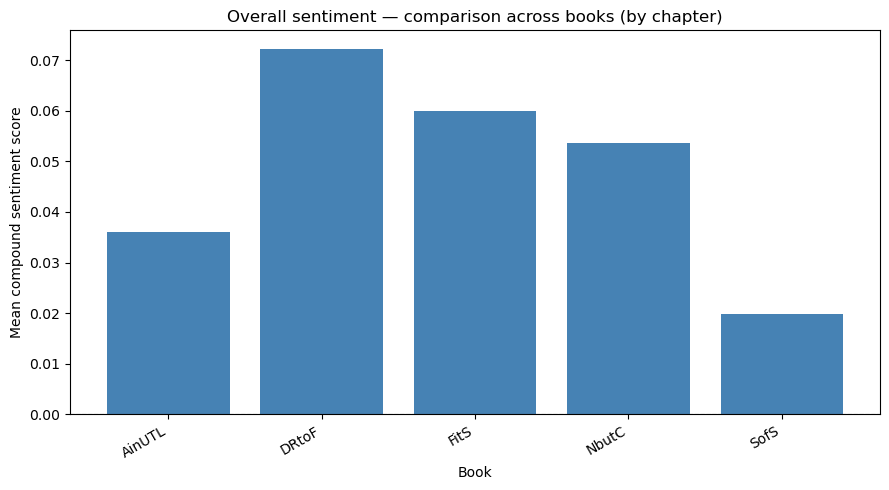

In [5]:
# >>> Set to a list of book names to restrict, or None for all
BOOKS_FOR_SENTIMENT = ["SofS", "FitS", "DRtoF", "AinUTL", "NbutC"]

entry_sentiment = score_sentiment(db, books_to_plot=BOOKS_FOR_SENTIMENT, group_by="chapter")

---
## 4 · Bigrams

In [21]:
# >>> Change to any key in book_dfs; adjust n as needed
top_ngrams(list(book_dfs.keys())[0], book_dfs, n=15, ngram=1, use_stop_words=False)  # unigrams
top_ngrams(list(book_dfs.keys())[0], book_dfs, n=15, ngram=2, use_stop_words=False)  # bigrams
top_ngrams(list(book_dfs.keys())[0], book_dfs, n=15, ngram=3, use_stop_words=False)  # trigrams

TypeError: top_ngrams() got an unexpected keyword argument 'use_stop_words'

---
## 5 · Keyword-in-context

In [9]:
# >>> Edit keyword and book_name (or set book_name=None to search all books)
keyword_in_context("soldier", db, book_name=None, max_results=5)

Found 47 sentence(s) containing 'soldier'.

  [AinUTL / ch10_e8]
  Soldiers were there, standing guard while men were drawing water from where the river does not freeze.

  [AinUTL / ch10_e8]
  “Madame la Courge eludes you, mademoiselle,” called out one of the soldiers, but it was in good fun.

  [AinUTL / ch10_e15]
  More and more soldiers of the Carignan-Salières Regiment are being brought back from Fort St.-Louis.

  [AinUTL / ch12_e4]
  “Excellent, mademoiselle,” one of the soldiers cheered.

  [AinUTL / ch13_e1]
  There is a little shelter there for the soldiers who stand guard.
